# TD 5: Comparison test of two means from two paired samples

Christelle Gonindard & Matthias Grenié

**Session objective:
To understand the concept of tests for the comparison of two paired samples**.

As with the comparison of two independent samples, the choice of test when comparing two
of two paired samples will depend on the conditions of application.

1. if the sample size is >= 30: Student's parametric test for paired data is applied.
2. if the sample size is < 30, there are two possibilities:
    - if the data follow a normal distribution: Student's t test for paired data
    - if normality is not verified: Wilcoxon test (non-parametric)

## 1. Student's parametric test for paired data 

### 1.1 Data presentation

This dataset contains the results of serum hormone levels, expressed in
ng/mL, obtained from n=15 blood samples, using 2 assay techniques A and B.

**The question is as follows: Do the two assays differ?**

The data are contained in the file : `TD05_serum_dosing.txt` in the `data/` folder.

1. Read the data
2. Present the data
3. Make your first hypotheses

In [6]:
# Read data
serum = read.table("data/TD05_serum_dosing.txt", header = TRUE)

# Display start of data table
head(serum)

,id,A,B
,<int>,<int>,<int>
1,1,22,26
2,2,27,24
3,3,12,14
4,4,33,39
5,5,14,17
6,6,52,61


[1] 42.86667

[1] 47.86667

[1] 15

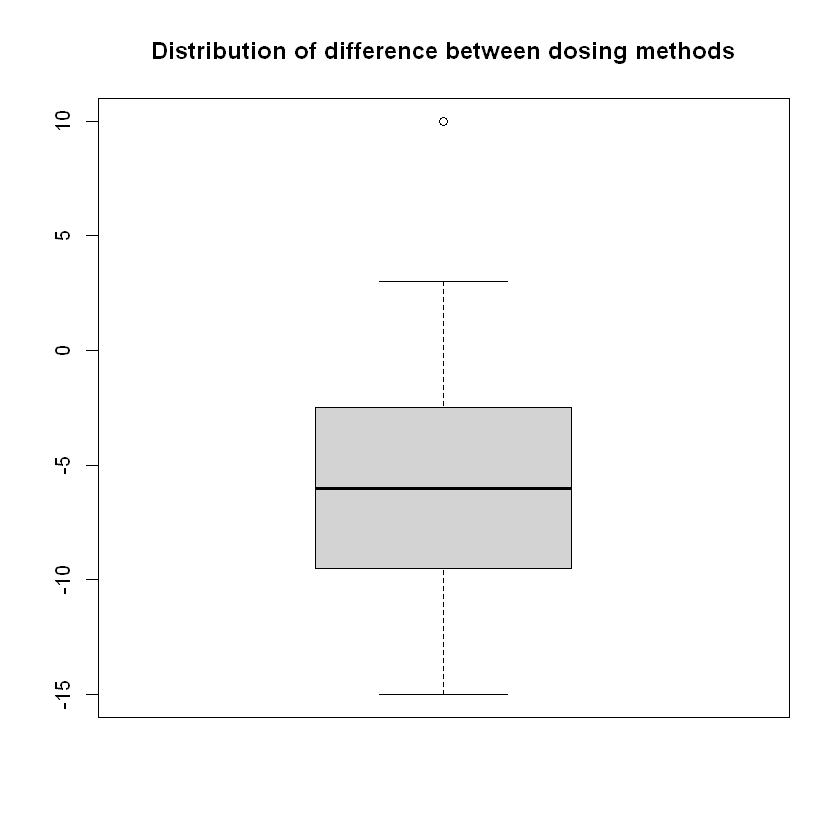

In [7]:
# Average A dosage
mean(serum$A)

# Average of dosage B
mean(serum$B)

# Calculation of average of A-B differences
d = serum$A - serum$B

# Boxplot(d)
boxplot(d, main = "Distribution of difference between dosing methods")

# Sample size
length(d)

**Comment**:

We see that d is mostly negative with a median close to -5 which suggests that method B finds higher dosage than method A.

### 1.2. Principle of Student's paired-data test

In this case, if the two techniques are identical, then the d values representing the difference
difference between the two assays should be equal to 0, which again means that the mean
mean of the differences $\mu _d$ should also be equal to 0, which is our H0 hypothesis.

The principle of this test is as follows: it will check whether $\mu _d$ is sufficiently far from 0 with a certain risk of error $\alpha$.
risk of error $\alpha$ for the two techniques to be considered significantly different.
different.

The test therefore calculates the difference between $\mu _d$ and 0 and divides by its standard deviation to normalize:

$$ \text{t} = \frac{\mu _d - 0}{\frac{S_d}{\sqrt {n}}}$$
 
### 1.3. Hypothesis of the paired Student's t test


Specify Hypotheses H0 and H1

H0 : the average of the difference between A and B is equal to 0 (d = 0)

H1 : the average of the difference between A and B is different from 0 (d ≠ 0)

## 4. Application condition

- none if $n \ge 30$.
- if $n < 30$, the difference random variable $d$ must be normally distributed.

In this case, it is important to check that the difference between the two dosages follows a normal distribution, since the sample size is 15.

We'll apply Shapiro's test to the difference between A and B:

H0 : The difference d follows a normal distribution

H1 : the difference d doesn't follow a normal distribution

In [8]:
# Shapiro's test
shapiro.test(d)


	Shapiro-Wilk normality test

data:  d
W = 0.95706, p-value = 0.6414


**Conclusion**:

We see p = 0.64 >>> alpha = 0.05, so we can't reject H0, meaning that the difference d follows a normal distribution

Plot the theoretical and observed quantiles of the Normal distribution 

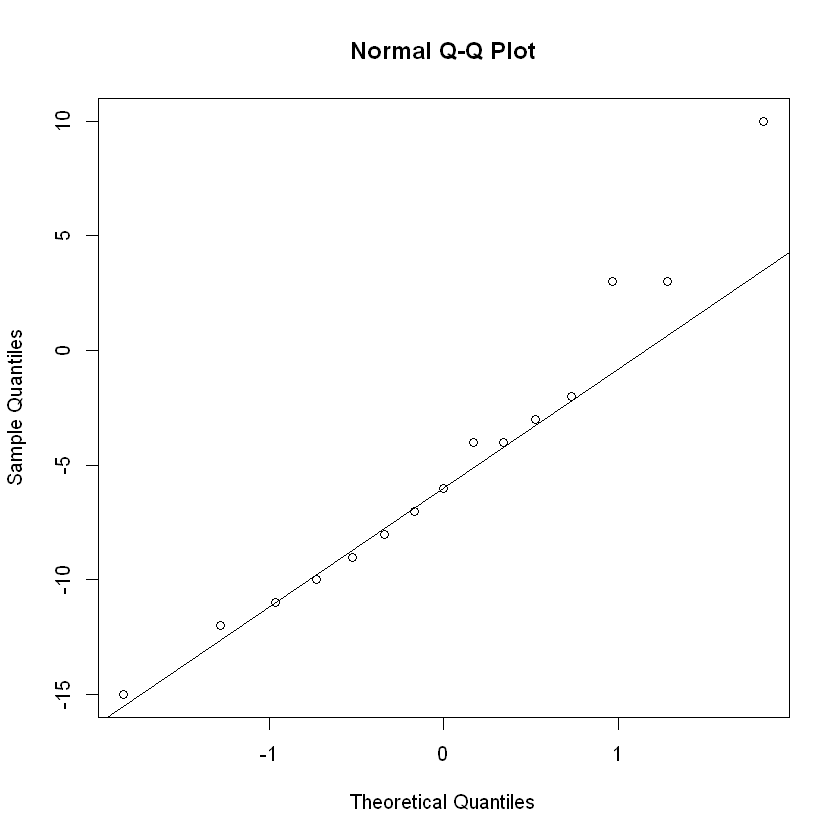

In [9]:
qqnorm(d)
qqline(d)

**Conclude**

The difference follows a normal distribution so we can perform the t-test.

### 1.5. Student's t test for paired data

In [10]:
# Student's t-test
t.test(d)
# or
t.test(d, m = 0)
# or
t.test(serum$A, serum$B, paired = TRUE)


	One Sample t-test

data:  d
t = -2.9385, df = 14, p-value = 0.01079
alternative hypothesis: true mean is not equal to 0
95 percent confidence interval:
 -8.64944 -1.35056
sample estimates:
mean of x 
       -5 



	One Sample t-test

data:  d
t = -2.9385, df = 14, p-value = 0.01079
alternative hypothesis: true mean is not equal to 0
95 percent confidence interval:
 -8.64944 -1.35056
sample estimates:
mean of x 
       -5 



	Paired t-test

data:  serum$A and serum$B
t = -2.9385, df = 14, p-value = 0.01079
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 -8.64944 -1.35056
sample estimates:
mean difference 
             -5 


**Conclusion** :

We observe p = 0.012 < alpha = 0.05, so we reject H0, which means that d is different than 0, so the A and B dosing methods differ.

## 2. Wilcoxon non-parametric test

### 2.1 Test principle

Like the Mann-Whitney test, it works on ranks. The samples (assumed to be
A and B) are matched, the test proceeds schematically as follows:
1. For each individual, it calculates the difference between its value in sample A and its value in sample B.
2. it calculates the rank of the differences in absolute value
3. it calculates the sum of ranks with a positive difference ($R^+$) and the sum of ranks with a negative value ($R^-$)
4. then tests whether the number of positive differences is significantly different from the number of negative differences (higher or rarer for one-tailed tests).

Example:  
The following table gives the results of a seric hormone in ng⋅dL⁻¹ on 15 people with two different dosing techniques (A and B).  
Our main question is to know if the two techniques give similar results

|      Patient ID |    1 |     2 |  3 |  4 |  5 |  6 |  7 |   8 |     9 |    10 | 11 |  12 |       13 |   14 | 15 |
|-----------------|------|-------|----|----|----|----|----|-----|-------|-------|----|-----|----------|------|----|
|        Method A | 22   |  27   | 12 | 33 | 14 | 52 | 44 |  68 |  48   |  72   | 35 |  80 |   75     | 19   | 42 |
|        Method B | 26   |  24   | 14 | 39 | 17 | 61 | 52 |  80 |  45   |  82   | 42 |  95 |   65     | 23   | 53 |
|     $d_{A - B}$ | -4   | **3** | -2 | -6 | -3 | -9 | -8 | -12 | **3** | -10   | -7 | -15 | **10**   | -4   | -9 |
| $\|d_{A - B}\|$ |  4   | **3** |  2 |  6 |  3 |  9 |  8 |  12 | **3** |  10   |  7 |  15 | **10**   |  4   |  9 |
| Global rank     |  5.5 | **3** |  1 |  7 |  3 | 10 |  9 |  14 | **3** |  11.5 |  8 |  15 | **11.5** |  5.5 | 13 |  

Sum of positive ranks (in **bold** in the table above): $R^+ = 3 + 3 + 11.5 = 17.5$

Sum of negative ranks: $R^- = 102.5$

Based on this comparison we see that we higher values of negative ranks than positive ranks. If both methods were similar then we should see similar sums of ranks as the differences should as much positive as negative.

### 2.2 Example: Comparing the effect of two drugs

We want to test the effects of two drugs on sleep, hyosciamyne and scopolamine. 

Is one of the two drugs a more potent sleep aid at the 5% threshold? The drugs were administered
to 10 patients.

The time each patient slept without drug and after administration of 0.6 mg of one and then the other drug was measured. A one-week delay was allowed between each measurement to allow the effect of the drugs to be completely eliminated. The values given in the table below correspond to the additional sleep time in the presence of the drug compared with the usual sleep time.

Compare the effect of the two drugs on sleep.

The data are in the text file `TD05_sleeping_pills.txt` in the `data/` folder.

1. Data loading


In [11]:
# Load data
pills = read.table("data/TD05_sleeping_pills.txt", header = TRUE)

# Show the first few rows
head(pills)

,patient,hyoscyamine,scopolamine
,<int>,<dbl>,<dbl>
1,1,0.7,1.9
2,2,-1.6,0.8
3,3,-0.2,1.1
4,4,-1.2,0.1
5,5,-0.1,-0.1
6,6,3.4,4.4


2. Describe the data

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  -4.60   -1.70   -1.30   -1.58   -1.05    0.00 

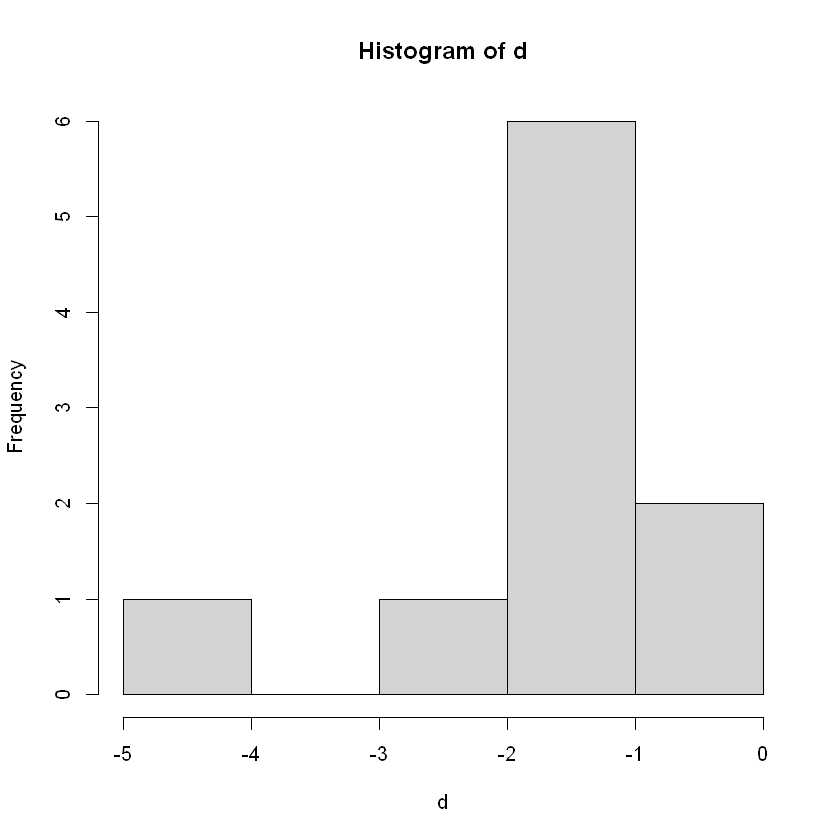

In [12]:
# Calculation of the difference d
d = pills$hyoscyamine - pills$scopolamine

# Statistical summary of d
summary(d)

# Graphical visualization of d
hist(d)

**Conclude**

It seems that d is mostly negative which means that hyoscyamine doesn't increase sleep as much as scopolamine.

3. Verification of the normality of **d**

Specify hypotheses H0 and H1

H0 : d follows a normal distribution

H1 : d doesn't follow a normal distribution

In [13]:
# Shapiro test
shapiro.test(d)


	Shapiro-Wilk normality test

data:  d
W = 0.82987, p-value = 0.03334


**Conclude**

We see p = 0.033 < alpha = 0.05, so we reject H0, which means d doesn't follow a normal distribution.
So we can't perform a paired t-test. We need to work on a non-parametric test.

For this we will perform the non-parametric Wilcoxon test for small samples.

4. Performing the Wilcoxon test for paired data

We want to check whether **scopolamine** is more effective than **hyoscyamine**, so we're going to do a one-tailed test.

Specify hypotheses H0 and H1 :

H0 : scopolamine has the same efficiency as hyoscyamine

H1 : scopolamine is more efficient than hyoscyamine


In [14]:
# Wilcoxon test for paired data
wilcox.test(pills$scopolamine, pills$hyoscyamine, paired = TRUE, alternative = "greater")

Warning message in wilcox.test.default(pills$scopolamine, pills$hyoscyamine, paired = TRUE, :
"impossible de calculer la p-value exacte avec des ex-aequos"
Warning message in wilcox.test.default(pills$scopolamine, pills$hyoscyamine, paired = TRUE, :
"impossible de calculer une p-value exacte avec des zéros"



	Wilcoxon signed rank test with continuity correction

data:  pills$scopolamine and pills$hyoscyamine
V = 45, p-value = 0.004545
alternative hypothesis: true location shift is greater than 0


**Conclusion**  
We observe p = 0.005 < alpha = 0.05, so we reject H0 which means that scopolamine is more efficient than hyoscyamine.

**Note: for the Wilcoxon test, the `wilcox.test()` function must be used for paired data by specifying the instruction
`paired = TRUE`**


## 3. Application exercises

### Exercise 1

Dorbienal is a new sleeping pill. Having demonstrated that their molecule is harmless
molecule, the laboratory hopes to prove its efficacy. To do this, it is launching a test on a cohort of
of 16 people. The protocol is as follows:
1. The sleep time of the 16 people is measured every day for a week (control period).
2. Patients are then treated for 15 days with dorbienal.
3. Treatment is extended for a further week, during which their sleep time is measured again (treatment period).

Throughout the experiment, patients are asked to adhere to a constant bedtime of
at 11 p.m.
- Question 1: Do you think this protocol is appropriate for studying the effectiveness of dorbienal?
- Question 2: What is the main feature of this dataset, and what is the main advantage of this type of dataset?
- Question 3: Is dorbienal effective? Answer for a threshold of 1% and 5% and conclude.

The data are contained in the file `TD05_dorbienal.txt` in the `data/` folder.

**Question 1**:  
The protocol seems good as the same people are measured with and without treatment so that the effect of individuals doesn't affect the sleep duration.

**Question 2**:  
As said above, this is a paired dataset so it's useful.

**Question 3**:

In [17]:
dorbienal = read.table("data/TD05_dorbienal.txt", header = TRUE)
head(dorbienal)

# We want to perform a paired Student's test
# Let's look at the sample size
dim(dorbienal)

# n = 15, let's check the normality of the difference 'd'
d = dorbienal$treatment - dorbienal$control

# Shapiro test with the usual hypotheses
shapiro.test(d)

# p >>> 0.05, so we can't reject H0, and the difference 'd' follow a Normal distribution

# Let's perform Student's test
t.test(d, alternative = "greater")

# p = 0.01 so at the 5% threshold we reject H0 so we conclude that the treatment is more efficient than the control (= increase sleep duration)
# at the 1% threshold the answer is not as clear and we cannot really conclude

,id,control,treatment
,<int>,<dbl>,<dbl>
1,1,7.30,7.50
2,2,6.22,7.22
3,3,6.44,5.04
4,4,7.45,8.33
5,5,6.97,7.32
6,6,6.60,7.67


[1] 15  3


	Shapiro-Wilk normality test

data:  d
W = 0.90731, p-value = 0.1232



	One Sample t-test

data:  d
t = 2.6026, df = 14, p-value = 0.01044
alternative hypothesis: true mean is greater than 0
95 percent confidence interval:
 0.1687405       Inf
sample estimates:
mean of x 
    0.522 


### Exercise 2: 

The heart rate (HR) of fifteen subjects is measured before and after a two-minute
to a two-minute test in which they were exposed to noises louder than
80 decibels. 


Do the results of this experiment, contained in the file `TD05_exercise_2.txt` in the `data/` folder, allow us to conclude, with a risk of error of $\alpha$=5% and a risk of 1%, that the sound test has an effect on heart rate?


In [ ]:
hr = read.table("data/TD05_exercise2.txt", header = TRUE)
head(hr)

# Compute the difference 'd'
d = hr$x2 - hr$x1

length(d)
# n = 15 < 30 so we need to check normality

qqnorm(d)
qqline(d)
# We see some deviations
shapiro.test(d)
# We see p = 0.036 so at the 5% threshold we would reject H0 but not at the 1% threshold, so it's no so clear...
# Let's perform a non-parametric test instead

# H0: the sound has no effect on heart rate
# H1: the sound has an effect (increase or decrease heart rate)
wilcox.test(d)
# or
wilcox.test(hr$x2, hr$x1, paired = TRUE)

# => p = 0.004 < alpha = 0.05 and 0.01, so in both cases we reject H0, which means the sound has an effect on the heart rate of participants
# We could have performed a one-sided test to test in which direction it has an effect

,subject,x1,x2
,<int>,<int>,<int>
1,1,90,95
2,2,73,77
3,3,82,90
4,4,92,95
5,5,87,81
6,6,68,90


[1] 15


	Shapiro-Wilk normality test

data:  d
W = 0.87219, p-value = 0.03634


Warning message in wilcox.test.default(d):
"impossible de calculer la p-value exacte avec des ex-aequos"



	Wilcoxon signed rank test with continuity correction

data:  d
V = 110.5, p-value = 0.00437
alternative hypothesis: true location is not equal to 0


Warning message in wilcox.test.default(hr$x2, hr$x1, paired = TRUE):
"impossible de calculer la p-value exacte avec des ex-aequos"



	Wilcoxon signed rank test with continuity correction

data:  hr$x2 and hr$x1
V = 110.5, p-value = 0.00437
alternative hypothesis: true location shift is not equal to 0
